In [28]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import re

****ĐỌC DATASET VÀ TỔNG QUAN VỀ DATASET TRƯỚC XỬ LÝ LÀM SẠCH****

In [29]:

# Đường dẫn dữ liệu
RAW_DATA_PATH = os.path.join('..', '..', 'data', 'raw', 'steamspy_games_4000.csv')
PROCESSED_DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'pc_cleaned.csv')
IAP_PATH = os.path.join('..', '..', 'data', 'external', 'genre_revenue_2024_2025.csv')
df = pd.read_csv(RAW_DATA_PATH)
display(df)

print(f"Cac cot hien co: {df.columns.tolist()}")
print(df.info())
print(df.describe())
print(df.isna().sum())

,appid,name,genre,tags,game_mode,developer,publisher,release_date,release_year,owners,...,positive,negative,userscore,metacritic_score,ccu,average_forever,average_2weeks,median_forever,median_2weeks,score_rank
0,730,Counter-Strike: Global Offensive,"Action,Free To Play","FPS,Shooter,Multiplayer,Competitive,Action,Tea...","Multi-player,Cross-Platform Multiplayer,Steam ...",Valve,Valve,"Aug 21, 2012",2012,"100,000,000 .. 200,000,000",...,7642084,1173003,0,True,1013936,0,0,0,0,NaN
1,1172470,Apex Legends,"Action,Adventure,Free To Play","Free to Play,Battle Royale,Multiplayer,FPS,Sho...","Multi-player,PvP,Online PvP,Co-op,Online Co-op...",Respawn,Electronic Arts,"Nov 4, 2020",2020,"100,000,000 .. 200,000,000",...,668053,326926,0,False,124262,0,0,0,0,NaN
2,578080,PUBG: BATTLEGROUNDS,"Action,Adventure,Massively Multiplayer,Free To...","Survival,Shooter,Battle Royale,Multiplayer,FPS...","Multi-player,PvP,Online PvP,Stats,Remote Play ...",PUBG Corporation,"KRAFTON, Inc.","Dec 21, 2017",2017,"100,000,000 .. 200,000,000",...,1520457,1037487,0,False,314682,0,0,0,0,NaN
3,1623730,Palworld,"Action,Adventure,Indie,RPG,Early Access","Open World,Survival,Creature Collector,Multipl...","Single-player,Multi-player,Co-op,Online Co-op,...",Pocketpair,Pocketpair,"Jan 18, 2024",2024,"50,000,000 .. 100,000,000",...,358266,22443,0,False,18028,0,0,0,0,NaN
4,440,Team Fortress 2,"Action,Free To Play","Free to Play,Hero Shooter,Multiplayer,FPS,Shoo...","Multi-player,Cross-Platform Multiplayer,Steam ...",Valve,Valve,"Oct 10, 2007",2007,"50,000,000 .. 100,000,000",...,1044264,117208,0,True,43819,0,0,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,595780,Rogue Port - Blue Nightmare,"Action,Adventure,Indie,RPG","Action,Adventure,RPG,Indie,Pixel Graphics,RPGM...","Single-player,Steam Achievements,Full controll...",Volens Nolens Games,Volens Nolens Games,"Mar 31, 2017",2017,"100,000 .. 200,000",...,72,22,0,False,13,0,0,0,0,NaN
3996,2107280,LAZ3RZ,"Action,Casual,Indie,Sports,Free To Play,Early ...","Action,Shooter,Arena Shooter,FPS,First-Person,...","Multi-player,PvP,Online PvP",ARPSEL,ARPSEL,"Aug 24, 2022",2022,"100,000 .. 200,000",...,92,28,0,False,0,0,0,0,0,NaN
3997,796860,Police Enforcement VR : 1-King-27,"Action,Adventure,Casual,Indie,RPG,Simulation,E...","Simulation,Action,Adventure,Indie,Casual,RPG,E...","Single-player,Tracked Controller Support,VR On...",Karnage Gaming,Karnage Gaming,"Jun 8, 2018",2018,"100,000 .. 200,000",...,100,223,0,False,1,0,0,0,0,NaN
3998,1053000,PLANES ATTACK,"Action,Casual,Free To Play,Indie,Sports","Free to Play,Casual,Indie,Action,Sports,Flight...","Single-player,Steam Achievements,Full controll...",SRS Games,SRS Games,"May 6, 2019",2019,"100,000 .. 200,000",...,298,86,0,True,0,0,0,0,0,NaN


Cac cot hien co: ['appid', 'name', 'genre', 'tags', 'game_mode', 'developer', 'publisher', 'release_date', 'release_year', 'owners', 'price', 'initialprice', 'discount', 'positive', 'negative', 'userscore', 'metacritic_score', 'ccu', 'average_forever', 'average_2weeks', 'median_forever', 'median_2weeks', 'score_rank']
<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   appid             4000 non-null   int64  
 1   name              4000 non-null   str    
 2   genre             4000 non-null   str    
 3   tags              3749 non-null   str    
 4   game_mode         3764 non-null   str    
 5   developer         3987 non-null   str    
 6   publisher         3980 non-null   str    
 7   release_date      4000 non-null   str    
 8   release_year      4000 non-null   int64  
 9   owners            4000 non-null   str    
 10  price          

Sau các bước thống kê mô tả sơ bộ, ghi nhận **vai nhóm vấn đề cốt lõi** cần can thiệp trong pipeline ETL:
- Khuyết thiếu value: `tags` & `game_mode`: Xuất hiện tỷ lệ khuyết thiếu rất cao, `score_rank`:** Hầu như hoàn toàn trống, không có giá trị phân tích định lượng.
- Khuyết thiếu ngầm định dưới dạng gia tri "0" : Dữ liệu tồn tại rất nhiều giá trị `0` mang ý nghĩa dữ liệu bị thiếu hoặc chưa thu thập được.
-  Sai lệch kiểu dữ liệu & Định dạng phi chuẩn.

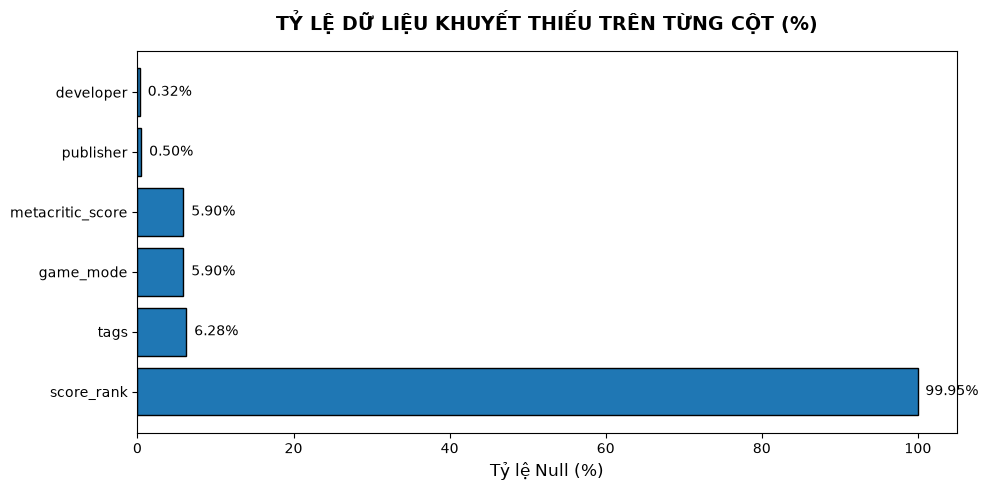

In [30]:
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100
null_summary = pd.DataFrame({
    'Tên Cột': df.columns,
    'Số lượng Null': null_counts.values,
    'Tỷ lệ Null (%)': np.round(null_pct.values, 2),
    'Kiểu dữ liệu': df.dtypes.values,
})
missing_cols = null_summary[null_summary['Số lượng Null'] > 0].sort_values(by='Số lượng Null', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.barh(
    missing_cols['Tên Cột'], 
    missing_cols['Tỷ lệ Null (%)'], 
    edgecolor='black'
)

plt.title('TỶ LỆ DỮ LIỆU KHUYẾT THIẾU TRÊN TỪNG CỘT (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tỷ lệ Null (%)', fontsize=12)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center')

plt.tight_layout()
plt.show()


- Loại bỏ cột `score_rank`: Cột này bị khuyết thiếu gần như tuyệt đối do đó được loại bỏ hoàn toàn thay vao do xây dựng chỉ số `Standardized_Rating` (Thang 0 - 100) tính toán tỷ lệ đánh giá tích cực từ người chơi thông qua cột `positive`, `negative`.
- Ccác cột còn lại: được điền giá trị mặc định là `Unknown`.

In [31]:
# Kiểm tra 1 số cột cốt lõi 

print(df['owners'].value_counts())
print(df[['positive', 'negative', 'userscore']].describe())
print(df[['price', 'initialprice', 'discount']].describe())
print(df['genre'].value_counts().head(10))

print('----')
print(df[['score_rank', 'average_forever', 'average_2weeks', 'median_forever', 'median_2weeks']].describe())

owners
200,000 .. 500,000            1425
100,000 .. 200,000             990
500,000 .. 1,000,000           634
1,000,000 .. 2,000,000         467
2,000,000 .. 5,000,000         293
5,000,000 .. 10,000,000         94
10,000,000 .. 20,000,000        53
20,000,000 .. 50,000,000        32
50,000,000 .. 100,000,000        9
100,000,000 .. 200,000,000       3
Name: count, dtype: int64
           positive      negative    userscore
count  4.000000e+03  4.000000e+03  4000.000000
mean   2.282855e+04  3.755261e+03     0.041000
std    1.486587e+05  2.839756e+04     1.856254
min    0.000000e+00  0.000000e+00     0.000000
25%    7.952500e+02  1.950000e+02     0.000000
50%    2.677500e+03  5.180000e+02     0.000000
75%    9.617500e+03  1.765500e+03     0.000000
max    7.642084e+06  1.173003e+06    95.000000
             price  initialprice     discount
count  4000.000000   4000.000000  4000.000000
mean   1265.464250   1480.015500     9.331500
std    1350.828339   1470.281102    24.327116
min       

Sau hàng loạt các phép thống kê kiểm tra các cột cốt lõi, ta có thể thấy 1 số vấn dề hiện ra như sau:
- Cột `owners` (số người sở hữu game) đang là kiểu dữ liệu `str` và không phù hợp để tính toán trực tiếp và ở cột này giá trị được ghi là 1 khoảng xác định sẽ gây ra sự tượng trưng về giá trị.
- Ở cột `userscore` giá trị trung bình chỉ đạt ~0.04 trên 4000 dòng, lần lượt các giá trị ở phân vị 25%, 50%, 75% đều là `'0.0'` có thể suy đoán ra toàn bộ cột này có tới hơn 90% là giá trị 0.
- Lần lượt các cột `price`, `initial-price` và `discount` chưa đưa về đơn vị chuẩn của toàn bộ dữ liệu của project.
- Các cột `genre` của mỗi game chứa rất nhiều giá trị thể loại điều này gây ra khó khăn đến những phân tích liên quan đến thể loại khiến mất can bằng bộ dữ liệu.
- Các cột `score_rank`, `average_forever`, `average_2weeks`, `median_forever`, `median_2weeks` đều bị missing hoặc toàn giá trị '0'.

**Điều cần làm bây giờ là tổng hợp lại những thứ cần xử lý trước khi vào phân tích.**

### TỔNG HỢP CHI TIẾT CÁC CÔNG VIỆC CẦN XỬ LÝ (CLEANING ACTION PLAN)

Dựa trên các phát hiện từ bước kiểm toán dữ liệu, nhóm phân loại và xác lập 5 nhóm công việc tiền xử lý kỹ thuật cần thực hiện tuần tự như sau:

| Nhóm Xử Lý | Các Cột Liên Quan | Hiện Trạng Dữ Liệu | Thao Tác Kỹ Thuật (Giải Pháp) |
| :--- | :--- | :--- | :--- |
| **1. Loại bỏ cột** | `score_rank`<br>`average_forever`<br>`average_2weeks`<br>`median_forever`<br>`median_2weeks`<br>`metacritic_score`<br>`userscore` | • `score_rank` khuyết thiếu 99.95%<br>• 4 cột playtime 100% bằng giá trị `0`<br>• `metacritic_score` là cờ Boolean, không phải điểm<br>• `userscore` có ~99.9% là giá trị `0` | **Drop hoàn toàn 7 cột này** khỏi DataFrame để giải phóng bộ nhớ và tránh gây nhiễu phân tích. |
| **2. Điền khuyết (Imputation)** | `developer`<br>`publisher`<br>`tags` | • `developer` khuyết 13 dòng (0.33%)<br>• `publisher` khuyết 20 dòng (0.50%)<br>• `tags` khuyết 251 dòng (6.28%) | • Điền `developer` và `publisher` thiếu bằng chuỗi `"Unknown"`.<br>• Điền `tags` thiếu bằng chuỗi rỗng `""`. |
| **3. Quy đổi đơn vị & Đo lường** | `owners` $\rightarrow$ `Volume_Units`<br>`price`, `initialprice` $\rightarrow$ `price_usd` | • `owners` là chuỗi khoảng (vd: `"100,000,000 .. 200,000,000"`)<br>• `price` và `initialprice` đang ở đơn vị Cents | • Tách 2 cận của `owners`, tính trung bình cộng (Midpoint) gán vào `Volume_Units`.<br>• Chia `price` và `initialprice` cho `100.0` để chuyển về đơn vị USD. |
| **4. Tạo Calculated Fields chuẩn hóa** | `Harmonized_Revenue_USD`<br>`Standardized_Rating`<br>`Rating_Tier` | • Chưa có trường doanh thu chuẩn USD<br>• Chưa có thước đo điểm số chuẩn 0 - 100 | • Tính doanh thu: $\text{Harmonized\_Revenue\_USD} = \text{Volume\_Units} \times \text{price\_usd}$ *(Game Free = $0$)*.<br>• Tính điểm đánh giá chuẩn hóa: $\text{Standardized\_Rating} = \frac{\text{positive}}{\text{positive} + \text{negative}} \times 100$.<br>• Gán nhãn `Rating_Tier`: *Masterpiece* ($\ge 85$), *Great* ($75 - 84$), *Mixed* ($50 - 74$), *Poor* ($< 50$). |
| **5. Chuẩn hóa phân loại & Khớp Schema** | `genre`<br>`Platform_Category` | • `genre` dính nhiều nhãn phụ (`Free To Play`, `Indie`, `Early Access`)<br>• Chưa có định danh nền tảng chuẩn | • Viết hàm bóc tách lấy thể loại gameplay cốt lõi (Action, RPG, Strategy, Shooter...).<br>• Gán giá trị cố định: `Platform_Category = 'PC'`. |

In [32]:
# Xu ly cot owners lay trung binh 2 can khoang
def parse_owners(val):
    if pd.isna(val):
        return 0.0
    num = re.findall(r'\d+', val.replace(',', ''))
    if len(num) == 2:
      return (float(num[0]) + float(num[1])) / 2.0
    elif len(num) == 1:
      return float(num[0])
    return np.nan

df['Volume_Units'] = df['owners'].apply(parse_owners)

df['price_usd'] = df['price'].fillna(0).astype(float) / 100.0
df['initial_price_usd'] = df['initialprice'].fillna(0).astype(float) / 100.0


pos = df['positive'].fillna(0).astype(float)
neg = df['negative'].fillna(0).astype(float)
total_review = pos + neg

df['Rating'] = np.where(
   total_review > 0, np.round(pos/total_review, 2) * 100, np.nan
)

def get_tier(score):
  if score >= 85.0:
    return 'Masterpiece'
  elif score >= 75.0:
    return 'Great'
  elif score >= 50.0:
    return 'Mixed'
  else:
    return 'Poor'

df['Rating_Tier'] = df['Rating'].apply(get_tier)

# Xu ly genre
main_genre = {
    "Action",
    "Arcade",
    "Casino",
    "Lifestyle",
    "Puzzle",
    "RPG",
    "Racing",
    "Simulation",
    "Sports",
    "Strategy",
    "Shooter",
    "Tabletop",
}

genre_mapping = {
    "Action": "Action",
    "Adventure": "Action",
    "Fighting": "Action",
    "Platformer": "Arcade",
    "RPG": "RPG",
    "Strategy": "Strategy",
    "Puzzle": "Puzzle",
    "Casual": "Puzzle",
    "Simulation": "Simulation",
    "Shooter": "Shooter",
    "FPS": "Shooter",
    "Sports": "Sports",
    "Racing": "Racing",
    "Arcade": "Arcade",
    "Board Games": "Tabletop",
    "Card": "Tabletop",
}
genre_priority = [
    "Shooter",
    "RPG",
    "Strategy",
    "Simulation",
    "Racing",
    "Sports",
    "Puzzle",
    "Arcade",
    "Action",
    "Tabletop",
]

def map_genre(value):
      if pd.isna(value):
            return "Other"

      raw_genres = [
        genre.strip()
        for genre in str(value).split(",")
      ]

      mapped_genres = {
            genre_mapping[genre]
            for genre in raw_genres
            if genre in genre_mapping
      }

      # Chọn genre theo thứ tự ưu tiên
      for genre in genre_priority:
            if genre in mapped_genres:
                  return genre

      return "Other"
df['Genre'] = df['genre'].apply(map_genre)

genre_iap = pd.read_csv(IAP_PATH)
genre_volume = df.groupby('Genre')['Volume_Units'].sum()
genre_iap_lookup = genre_iap.set_index('Genre')['Steam_Revenue_2025_USD_Billion'] * 1e9
pc_iap_arpu = (genre_iap_lookup / genre_volume).replace([np.inf, -np.inf], np.nan)
df['IAP_Revenue_USD'] = (df['Volume_Units'] * df['PC_IAP_ARPU'].fillna(0))
df['Paid_Revenue_USD'] = df['Volume_Units'] * df['price_usd'] 

# Tinh doanh thu cuoi cung, cac game o tuc la Free to play
df['Harmonized_Revenue_USD'] = df['IAP_Revenue_USD'] + df['Paid_Revenue_USD'] = df['Volume_Units'] * df['price_usd'] 

df["Game_Title"] = df['name'].fillna('Unknow').astype(str).str.strip()
df["publisher"] = df['publisher'].fillna('Unknow').astype(str).str.strip()
df["developer"] = df['developer'].fillna('Unknow').astype(str).str.strip()
df['Platform_Category'] = 'PC'
df['Is_CrossPlatform'] = False
df['ccu'] = df['ccu'].fillna(0).astype(int)

SyntaxError: cannot assign to expression (3955962526.py, line 116)

In [ ]:
cols = ['Game_Title','Platform_Category','Genre',
    'publisher','developer','release_year','Volume_Units',
    'Harmonized_Revenue_USD','Rating','Rating_Tier',
    'Is_CrossPlatform',
    'price_usd',
    'discount',
    'positive',
    'negative',
    'ccu',
]

df_cleaned = df[cols].copy()
df_cleaned.to_csv(PROCESSED_DATA_PATH, index=False, encoding='utf-8-sig')